#### Exploratory Data Analysis - Trend and Multivariate Analysis
Here I'll perform trend and multivariate analysis to get the insights from the cleaned data.

#### Step-0: Setup

In [1]:
# Imports and load
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the data with dates (parse_dates tells which columns are dates)
df=pd.read_csv("../data/cleaned/charging_clean.csv", parse_dates=['StartDatetime','EndDatetime'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72088 entries, 0 to 72087
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   UserID          72088 non-null  int64         
 1   ChargerID       72088 non-null  int64         
 2   ChargerCompany  72088 non-null  int64         
 3   Location        72088 non-null  object        
 4   ChargerType     72088 non-null  int64         
 5   StartDatetime   72088 non-null  datetime64[ns]
 6   EndDatetime     72088 non-null  datetime64[ns]
 7   Duration        72088 non-null  int64         
 8   Demand          72088 non-null  float64       
dtypes: datetime64[ns](2), float64(1), int64(5), object(1)
memory usage: 5.0+ MB


In [3]:
# Creating time columns (needed for few questions in the analysis)
df['Hour']=df['StartDatetime'].dt.hour
df['Month']=df['StartDatetime'].dt.month
df['Weekday']=df['StartDatetime'].dt.day_name()
df['Date']=df['StartDatetime'].dt.date
df['IsWeekend']=df['StartDatetime'].dt.day_of_week>=5
df.head()

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDatetime,EndDatetime,Duration,Demand,Hour,Month,Weekday,Date,IsWeekend
0,0,1,1,hotel,0,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,20,9,Thursday,2022-09-15,False
1,0,1,1,hotel,0,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,20,9,Wednesday,2022-09-14,False
2,0,1,1,hotel,0,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,18,9,Wednesday,2022-09-14,False
3,0,1,1,hotel,0,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,18,9,Thursday,2022-09-29,False
4,0,1,1,hotel,0,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,19,9,Sunday,2022-09-25,True


#### Step-1: Trend Analysis

> **Q9. How does total daily and monthly demand change over the year? Is there a trend or a weekly pattern?**

In [4]:
# Month wise total demand
df['YearMonth']= df['StartDatetime'].dt.to_period('M')
monthly_total= df.groupby('YearMonth')['Demand'].sum().iloc[1:]
monthly_total

YearMonth
2021-10     64593.97
2021-11     71454.90
2021-12     84529.75
2022-01    109126.64
2022-02    102620.47
2022-03    103519.71
2022-04    104150.13
2022-05    115200.06
2022-06    117408.10
2022-07    139404.74
2022-08    142976.92
2022-09    111017.58
Freq: M, Name: Demand, dtype: float64

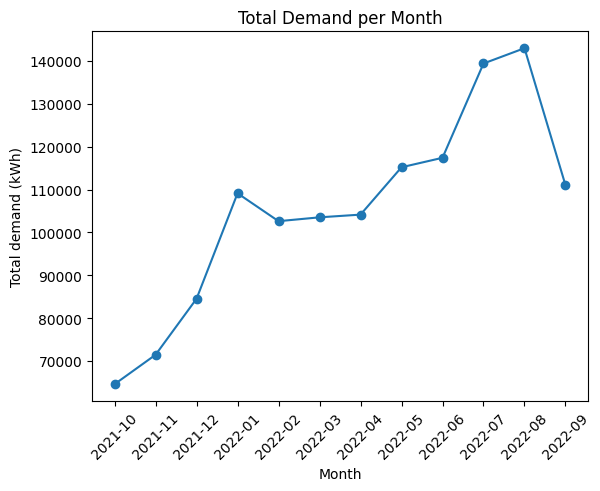

In [5]:
# Plotting monthly demand chart
plt.plot(monthly_total.index.astype(str), monthly_total.values, marker='o')
plt.title('Total Demand per Month')
plt.xlabel('Month')
plt.ylabel('Total demand (kWh)')
plt.xticks(rotation=45)
plt.show()

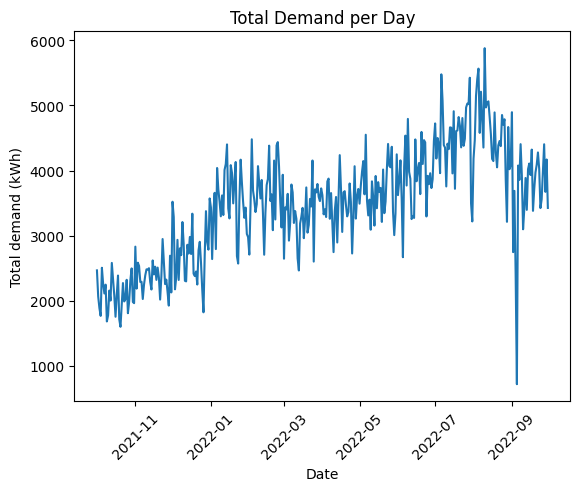

In [6]:
# Plotting daily demand chart
daily_total= df.groupby('Date')['Demand'].sum().iloc[1:]
plt.plot(daily_total.index, daily_total.values)
plt.title('Total Demand per Day')
plt.xlabel('Date')
plt.ylabel('Total demand (kWh)')
plt.xticks(rotation=45)
plt.show()

#### Observations: 
1. Daily demand rises over the year, from 2000–2500 kWh/day in Oct–Dec 2021 to about 3500 from Jan 2022 and about 4500 in Jul–Aug 2022. 
2. The line goes up and down every few days. As seen in Q6, weekdays (highest on Thursday) are busier than weekends (lowest on Sunday), so part of this up and down is a weekly pattern.
3. It means demand is growing over time, with a weekly pattern.

> **Q10. Are some users and chargers used much more than others? Are there underused chargers?**


In [7]:
# Top users
user_sessions = df['UserID'].value_counts().sort_values(ascending=False)
user_sessions.head()

UserID
0      31210
31       352
95       348
179      338
40       323
Name: count, dtype: int64

In [8]:
# Checking UserId 0
(df['UserID']==0).mean()*100, df[df['UserID']==0]['ChargerID'].nunique()

(np.float64(43.294306958162245), 309)

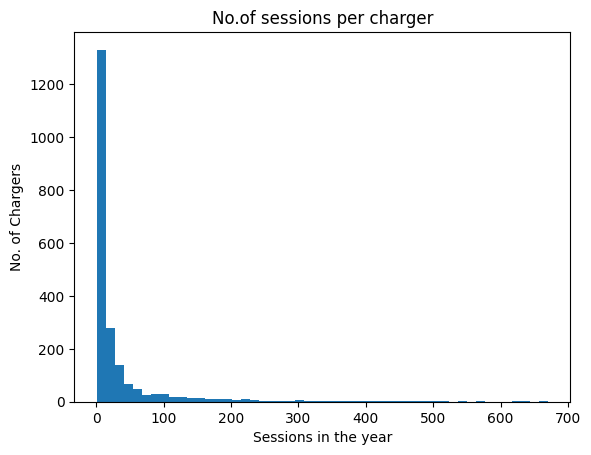

In [9]:
charger_sessions= df['ChargerID'].value_counts()
plt.hist(charger_sessions, bins=50)
plt.title('No.of sessions per charger')
plt.xlabel('Sessions in the year')
plt.ylabel('No. of Chargers')
plt.show()

In [10]:
# Busy vs Underused chargers
charger_sessions.describe(), (charger_sessions<=5).sum()

(count    2115.000000
 mean       34.084161
 std        74.847145
 min         1.000000
 25%         3.000000
 50%         9.000000
 75%        26.000000
 max       670.000000
 Name: count, dtype: float64,
 np.int64(804))

#### Observations: 
1. UserID 0 has 31,210 sessions (43% of all data) at 309 different chargers, so it's likely for unregistered users.. 
2. Among real users, half charged only 1–3 times, while a few charged over 300 times. 
3. For chargers, the median is only 9 sessions in the year. The busiest had about 670, while 804 chargers (38%) had 5 or fewer sessions.

#### Step2: Multivariate Analysis

> **Q11. How do charging sessions vary by location and hour together? For example, do hotels peak at night and companies during the day?**

In [17]:
# Getting top locations and then locations and hour wise % of sessions.
top6= df['Location'].value_counts().head(6).index
df_top= df[df['Location'].isin(top6)]

loc_hour= pd.crosstab(df_top['Location'], df_top['Hour'], normalize='index')*100
loc_hour.round(1)

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Location,,,,,,,,,,,,,,,,,,,,,
apartment,2.2,0.9,0.5,0.3,0.4,0.8,1.5,2.3,2.9,4.2,...,4.7,5.3,7.4,11.6,11.5,8.2,5.9,4.8,4.1,4.4
company,1.2,0.5,0.1,0.2,0.3,1.0,1.0,2.2,8.0,8.2,...,6.0,6.2,9.4,10.5,8.6,5.8,5.2,4.3,2.6,1.6
hotel,1.2,0.5,0.1,0.1,0.1,0.1,0.9,1.5,4.1,5.8,...,4.1,5.6,7.3,9.8,10.5,9.5,8.2,7.0,4.0,1.9
public area,1.3,0.8,0.4,0.1,0.3,1.0,2.3,4.4,6.9,6.4,...,5.5,5.5,6.4,7.6,7.7,6.1,5.3,5.0,3.1,2.8
public institution,0.8,0.5,0.3,0.2,0.5,1.1,1.9,4.4,7.8,5.9,...,5.9,6.8,7.3,6.3,6.6,5.9,5.1,4.5,2.5,1.3
resort,0.6,0.3,0.2,0.1,0.1,0.7,2.0,3.0,5.7,5.7,...,4.0,4.9,5.9,7.7,9.2,10.9,11.4,7.7,4.3,2.2


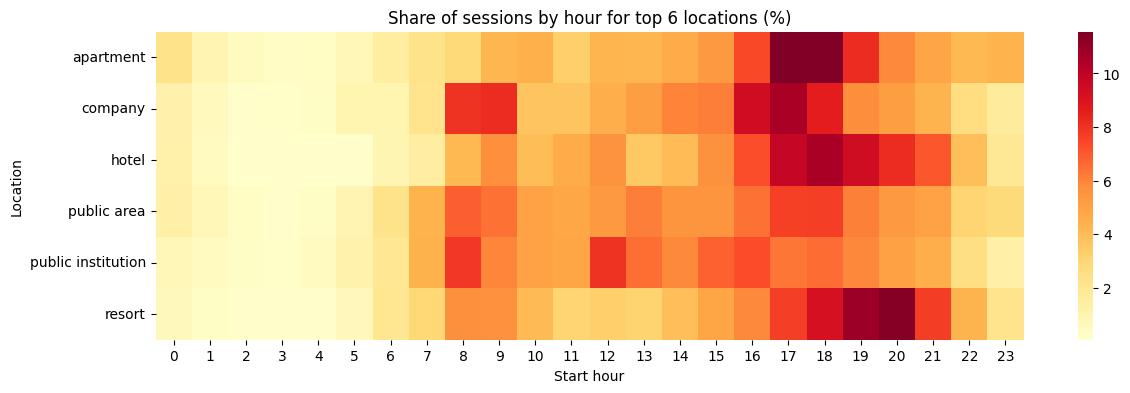

In [20]:
# Plotting the heatmap for the location and hour wise % of sessions
plt.figure(figsize=(14, 4))
sns.heatmap(loc_hour, cmap='YlOrRd')
plt.title('Share of sessions by hour for top 6 locations (%)')
plt.xlabel('Start hour')
plt.ylabel('Location')
plt.show()

#### Observations:

1. Apartment peaks at 5–6 pm (~11.5% each hour)means people charge when they get home from work.
2. Company has two peaks, 8–9 am (~8%) and 4–5 pm (~10%) means staff charge on arrival and before leaving.
3. Public institution is busiest in the morning (8 am) and at noon (12 pm, 8%) means during office and visiting hours.
4. Hotel peaks at 6 pm and stays high till 8 pm; resort peaks latest, at 7–8 pm (~11%) means guests charge after checking in or returning in the evening.
5. Public area is the most spread out (no hour above ~8%) means used through the whole day, not one fixed time.
6. Every location is nearly empty from 1–5 am.
7. Each location has its own busy hours, so charger planning and pricing should be set per location, not one rule for all. 
8. Example: More chargers or idle fees at apartments in the evening, and maintenance at any location between 1–5 am.

> **Q12. Does the effect of charger type on demand change across locations?**


In [25]:
# Pivot table showing location and charger type wise demand and difference by charging type
type_demand= df.pivot_table(index='Location', columns='ChargerType', values='Demand', aggfunc='median')
type_demand= type_demand.dropna()
type_demand['Difference']= type_demand[1]-type_demand[0]
type_demand.sort_values('Difference', ascending=False).round(2)

ChargerType,0,1,Difference
Location,,,
market,6.61,18.34,11.73
restaurant,12.80,24.44,11.64
sightseeing,6.54,17.93,11.39
public parking lot,8.96,16.79,7.83
resort,14.25,19.96,5.71
public institution,11.78,17.16,5.38
company,14.01,18.91,4.90
public area,12.82,16.98,4.16
apartment,14.25,18.12,3.88


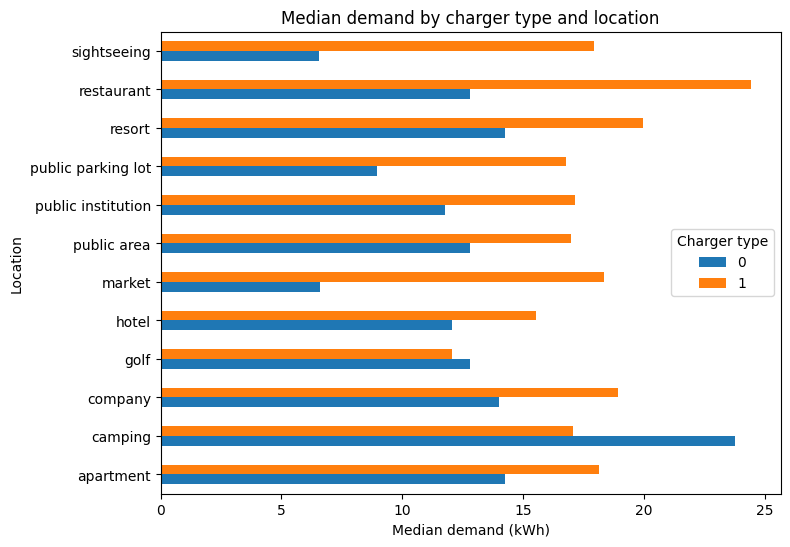

In [27]:
# Plotting bar chart for the location and charger type wise demand
type_demand[[0, 1]].plot(kind='barh', figsize=(8, 6))
plt.title('Median demand by charger type and location')
plt.xlabel('Median demand (kWh)')
plt.ylabel('Location')
plt.legend(title='Charger type')
plt.show()

#### Observations:

1. At most locations, type 1 sessions take more energy than type 0.
2. Type 1 is mostly same across locations (mostly 15.5–20 kWh). Type 0 changes a lot, from ~6.5 kWh (market, sightseeing) to ~24 kWh (camping).
3. The gap is biggest at market (11.7), restaurant (11.6) and sightseeing (11.4). At these places people stop for a short time, so type 0 (slow) delivers little energy, while type 1 (fast) can give a good charge in the same time.
4. At golf the two types are almost the same (12.8 vs 12.0).
5. At long-stay places like hotels and resorts, slow chargers are enough.

> **Q13. Which variables are most correlated with demand?**

In [28]:
# Checking correlation of all variables with demand 
corr = df[['Demand', 'Duration', 'ChargerType', 'ChargerCompany', 'Hour', 'Month', 'IsWeekend']].corr()
corr['Demand'].sort_values(ascending=False).round(2)

Demand            1.00
Duration          0.66
Hour              0.13
ChargerType       0.06
ChargerCompany    0.04
IsWeekend         0.01
Month            -0.01
Name: Demand, dtype: float64

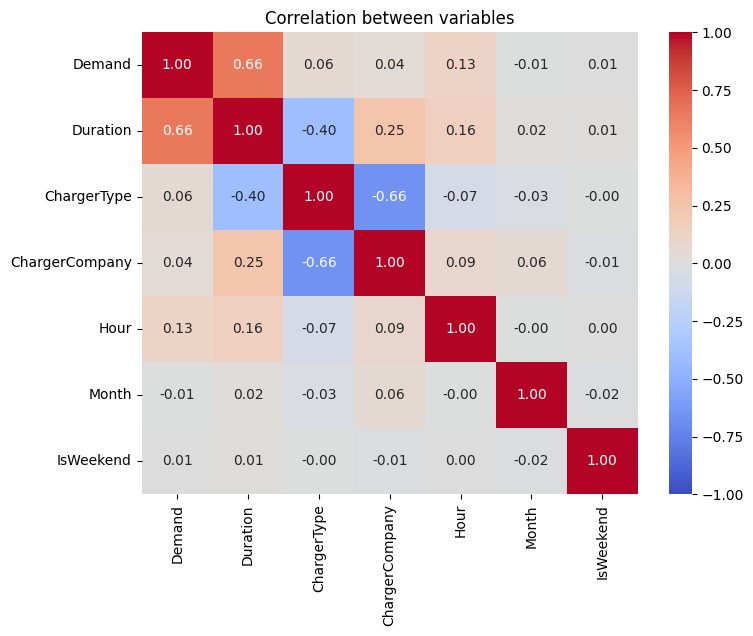

In [ ]:
# Plotting heatmap correlation chart
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between variables')
plt.show()

#### Observations:
1. Duration (0.66) is the only variable strongly related to demand; longer sessions deliver more energy. 
2. Hour (0.13) looks weak, but in Q6 demand clearly changed by hour (high late at night, low around noon). Correlation only measures a straight-line relationship.
3. ChargerType (0.06) and ChargerCompany (0.04) are weak overall, but Q12 showed charger type matters a lot at some locations. Correlation can't show effects that depend on another variable.
4. IsWeekend (0.01) and Month (−0.01) are close to zero; weekday/weekend and month barely change demand per session (matches Q8).
5. ChargerType and ChargerCompany (−0.66) are strongly related to each other: type 1 chargers exist only in company 0 (Q5).
6. Apart from Duration, no single variable has a strong straight line link with demand. Demand depends on combinations.

#### Step-3: Key Findings

##### Demand and duration
1. Demand is right-skewed. Median session uses 14.26 kWh, and about 84% of sessions use 30 kWh or less (Q1).
2. Most sessions last a few hours (median 114 min). A small group stays plugged in for very long, likely overnight (Q2).
3. Demand rises with duration for the first few hours, then flattens once the battery is full (Q7).
##### Charger type
4. Type 1 delivers more energy in much less time (about 33 kW vs 6.6 kW), so type 1 is most likely a fast charger. All type 1 chargers belong to company 0 (Q5).
5. Fast chargers make the biggest difference at short stop places (market, restaurant, sightseeing). At long-stay places like hotels and resorts, slow chargers are enough (Q12).
##### Where
6. Six locations cover about 82% of sessions. Apartments and public areas have the most sessions and the highest total demand (Q3, Q4).
7. Per session, long-stay places (camping, accommodation) use the most energy and short stops (market, sightseeing) the least (Q4).
##### When
8. Sessions peak at 5–6 pm, with a smaller peak at 8–9 am. Late-night sessions use the most energy per session (Q6).
9. Weekday and weekend demand is almost the same; only the timing changes (Q8).
10. Each location has its own busy hours: apartments 5–6 pm, companies morning and evening, public institutions morning and noon, hotels and resorts evening, public areas all day. All locations are nearly empty from 1–5 am (Q11).
##### Growth and usage
11. Daily demand grew from about 2000–2500 kWh/day (Oct–Dec 2021) to about 4500 (Jul–Aug 2022), with a weekly up and down (Q9).
12. UserID 0 makes up 43% of sessions and is likely unregistered users (Q10).
13. Charger use is very uneven: median 9 sessions a year, the busiest about 670, and 804 chargers (38%) had 5 or fewer (Q10).
##### What drives demand
14. Duration (0.66) is the only variable strongly related to demand. Other variables are weak on their own, but demand depends on combinations like hour, location and charger type (Q13).
#### Recommendations
1. Plan chargers and pricing per location, since each location peaks at different hours (Q11).
2. Add chargers or capacity at apartments and public areas, where total demand is highest (Q4).
3. Use idle fees at apartments in the evening peak so cars don't block chargers after they're full (Q7, Q11).
4. Put new fast chargers at short-stop places like markets, restaurants and sightseeing spots (Q12).
5. Do maintenance between 1–5 am, when almost no one charges (Q11).
6. Review the chargers with very few sessions: check their location, visibility or pricing (Q10).
7. Plan for growth, since daily demand roughly doubled in a year (Q9).